# Credit Card Fraud Detection — phase two

Flag rare fraud while making review capacity and missed-fraud uncertainty visible.

The full 284,807-row Worldline/ULB benchmark replaces the 50,000-row development sample for the new evaluation. Duplicate removal leaves 283,726 records and 473 fraud labels. Time is a split variable, never a predictor. The source remains linked by TensorFlow’s official tutorial; data rights are ODbL/DbCL.

This notebook executes the same standalone implementation; original notebooks are preserved.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from phase2 import run
summary = run()
summary

fraud: selected random_forest_sigmoid; AP=0.7882; log loss=0.0030; elapsed=25.49s


{'project': 'fraud',
 'input_file': 'transactions_full.csv',
 'input_sha256': '61171795e96ec102e4876a6809da8181dffd6d0d80a3fcce14d86a75643698e5',
 'rows_read': 284807,
 'rows_used': 283726,
 'duplicates_removed': 1081,
 'split_strategy': 'chronological 60/20/20; ties in Time stay together',
 'time_ranges': {'train': [0.0, 120392.0],
  'validation': [120393.0, 145233.0],
  'test': [145234.0, 172792.0]},
 'selected_model': 'random_forest_sigmoid',
 'threshold': 0.09111058040486575,
 'selection': 'validation AP; log loss breaks AP ties',
 'protocol': 'fit 45%, independent sigmoid calibration 15%, validation 20%, test 20%; grouped or chronological where available',
 'splits': {'fit': {'rows': 127672, 'positives': 255},
  'calibration': {'rows': 42563, 'positives': 87},
  'validation': {'rows': 56745, 'positives': 57},
  'test': {'rows': 56746, 'positives': 74}},
 'test': {'model': 'random_forest_sigmoid',
  'split': 'test',
  'average_precision': 0.7881522251306236,
  'roc_auc': 0.93898900

In [2]:
display(pd.read_csv('results/phase2/metrics.csv'))

,model,split,average_precision,roc_auc,log_loss,brier_score,accuracy,precision,recall,f1,threshold,tn,fp,fn,tp,alerts,positive_rate,rows
0,baseline,validation,0.001004,0.500000,0.008241,0.001004,0.998996,0.000000,0.000000,0.000000,0.500000,56688,0,57,0,0,0.001004,56745
1,weighted_logistic,validation,0.634817,0.927366,0.143121,0.038799,0.998837,0.453608,0.771930,0.571429,0.997537,56635,53,13,44,97,0.001004,56745
2,weighted_logistic_sigmoid,validation,0.634817,0.927366,0.003303,0.000563,0.998837,0.453608,0.771930,0.571429,0.020052,56635,53,13,44,97,0.001004,56745
3,random_forest,validation,0.771460,0.947742,0.006099,0.000433,0.999665,0.895833,0.754386,0.819048,0.333226,56683,5,14,43,48,0.001004,56745
4,random_forest_sigmoid,validation,0.771460,0.947742,0.002459,0.000318,0.999665,0.895833,0.754386,0.819048,0.091111,56683,5,14,43,48,0.001004,56745
5,baseline,test,0.001304,0.500000,0.010103,0.001303,0.998696,0.000000,0.000000,0.000000,0.500000,56672,0,74,0,0,0.001304,56746
6,weighted_logistic,test,0.702783,0.940422,0.121981,0.032772,0.999048,0.608696,0.756757,0.674699,0.997537,56636,36,18,56,92,0.001304,56746
7,weighted_logistic_sigmoid,test,0.702783,0.940422,0.003719,0.000612,0.999048,0.608696,0.756757,0.674699,0.020052,56636,36,18,56,92,0.001304,56746
8,random_forest,test,0.788152,0.938989,0.007367,0.000501,0.999559,0.901639,0.743243,0.814815,0.333226,56666,6,19,55,61,0.001304,56746
9,random_forest_sigmoid,test,0.788152,0.938989,0.002961,0.000411,0.999559,0.901639,0.743243,0.814815,0.091111,56666,6,19,55,61,0.001304,56746


In [3]:
display(Markdown(Path('results/phase2/REPORT.md').read_text()))

# Phase two: evidence and decision trade-offs

283,726 deduplicated observations. **random_forest_sigmoid** was selected using validation AP; log loss breaks AP ties.
fit 45%, independent sigmoid calibration 15%, validation 20%, test 20%; grouped or chronological where available. Calibration uses disjoint reserve labels; preprocessing fits only on fit rows.

| Test measure | Selected | Prior baseline |
|---|---:|---:|
| Average precision | 0.7882 | 0.0013 |
| Log loss | 0.0030 | 0.0101 |
| Brier score | 0.0004 | 0.0013 |
| Precision | 90.2% | 0.0% |
| Recall | 74.3% | 0.0% |

At the validation-selected threshold, 55 positives are found, 19 are missed, and 6 false flags occur.
95% Wilson recall interval: 63.3%–82.9%; precision: 80.2%–95.4%.
The intervals describe this benchmark sample under the stated sampling assumptions.

![Calibration reliability and bin support](reliability.png)
![Ranking budget and captured positives](ranking.png)

[Operating policies](operating_policies.csv) choose thresholds exclusively from validation scores for fixed workload budgets.
Ties stay together and can leave a budget partly unused. Applying the same thresholds to test can exceed the validation budget;
the table records actual counts. No dollar-saving or intervention-effect claim is inferred from these retrospective labels.

[Uncertainty](uncertainty.json) contains 200 bootstrap replicates, with clusters resampled when user/context groups exist.
[Validation stability](validation_stability.csv) tests a fixed model structure on three development-only splits.
[Subgroup errors](subgroup_errors.csv) gives support and missed/false-flag counts; small groups warrant caution.
[Error rows](errors.csv), [all candidate metrics](metrics.csv), [test predictions](predictions.csv), and [partition membership](splits.csv) are auditable.

The final test labels are not used to choose calibration, models, budgets, or thresholds. Previously published benchmark results
were known during redevelopment; an independent external evaluation remains necessary. Calibration assumes the same target population.
For CTR, calibration cannot undo unknown upstream negative sampling. For HR, observation dates and a departure horizon are missing;
feature-importance consistency is association, not causality. The fraud benchmark spans two days and anonymized PCA features.


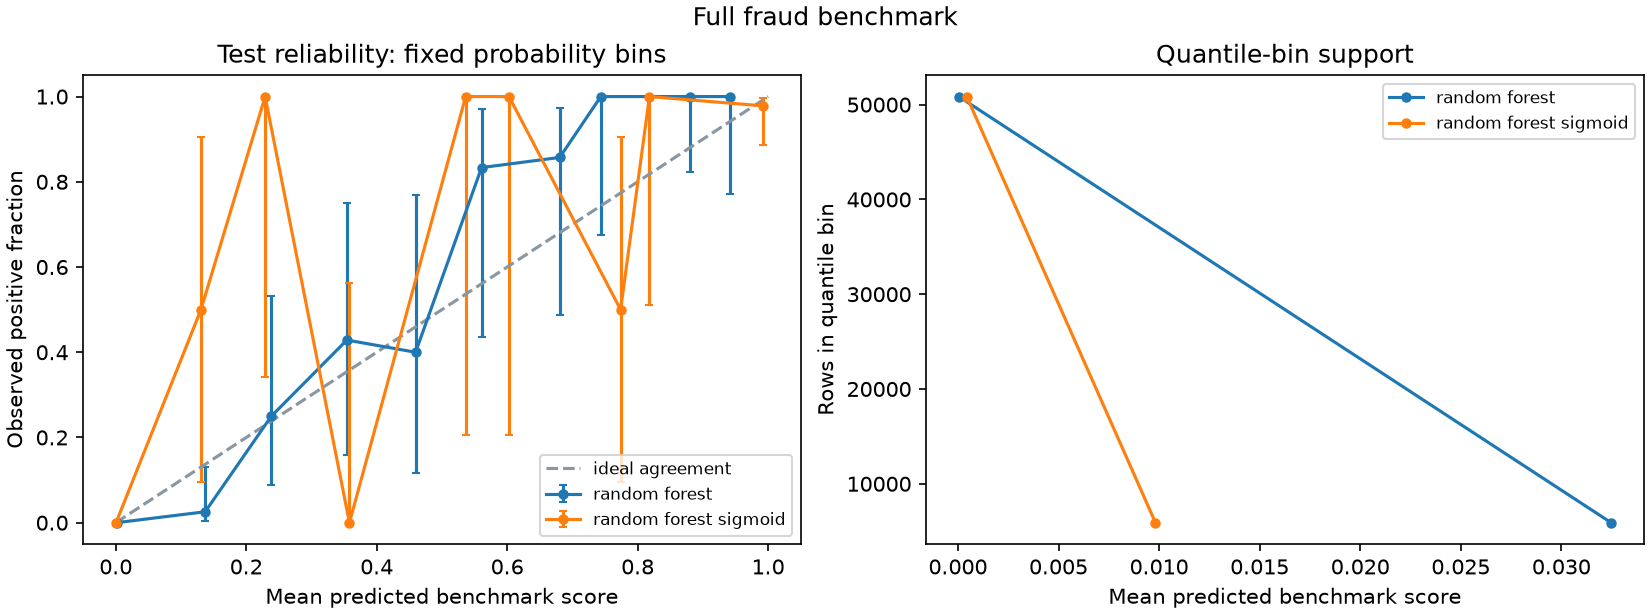

,fold,fit_rows,calibration_rows,validation_rows,average_precision,roc_auc,log_loss,brier_score,accuracy,precision,recall,f1,threshold,tn,fp,fn,tp,alerts,positive_rate,rows
0,1,85118,28371,37830,0.782162,0.962851,0.006418,0.000673,0.999286,0.828571,0.794521,0.811189,0.171850,37745,12,15,58,70,0.001930,37830
1,2,106397,35466,47287,0.806938,0.960546,0.003946,0.000624,0.999408,0.887500,0.788889,0.835294,0.092635,47188,9,19,71,80,0.001903,47287
2,3,127677,42559,56744,0.771169,0.947829,0.002462,0.000318,0.999665,0.895833,0.754386,0.819048,0.090807,56682,5,14,43,48,0.001005,56744


In [4]:
display(Image(filename='results/phase2/reliability.png'))
display(pd.read_csv('results/phase2/validation_stability.csv'))

In [5]:
json.loads(Path('results/phase2/uncertainty.json').read_text())

{'level': 0.95,
 'method': 'Class-stratified row bootstrap; conditional on observed class counts',
 'replicates': 200,
 'intervals': {'average_precision': {'low': 0.6985165053342393,
   'high': 0.8524658099084397},
  'f1': {'low': 0.7384615384615385, 'high': 0.8676950127877239},
  'log_loss': {'low': 0.0022971051717974402, 'high': 0.003906683964308152}},
 'recall_wilson': {'estimate': 0.7432432432432432,
  'low': 0.6334555586947143,
  'high': 0.8290229270043411,
  'n': 74},
 'precision_wilson': {'estimate': 0.9016393442622951,
  'low': 0.8015539278317405,
  'high': 0.9541354241845295,
  'n': 61},
 'limits': 'Wilson intervals assume independent rows; cluster bootstrap is used when IDs exist. Neither method establishes future-domain performance or accounts for two-day temporal dependence.'}

In [6]:
display(pd.read_csv('results/phase2/errors.csv').head(10))

,row_id,actual,selected_score,predicted,baseline_score,weighted_logistic_score,weighted_logistic_sigmoid_score,random_forest_score,random_forest_sigmoid_score
0,228883,1,0.018961,0,0.001997,0.999320,0.034549,0.232354,0.018961
1,231118,1,0.000969,0,0.001997,0.995007,0.014822,0.049012,0.000969
2,232390,1,0.025074,0,0.001997,0.999990,0.180476,0.249862,0.025074
3,237582,1,0.000572,0,0.001997,0.067712,0.000486,0.016667,0.000572
4,238617,1,0.014641,0,0.001997,0.973870,0.007221,0.216240,0.014641
5,239334,1,0.010978,0,0.001997,0.997846,0.021230,0.198367,0.010978
6,244437,1,0.000436,0,0.001997,0.002175,0.000106,0.000000,0.000436
7,244645,1,0.000436,0,0.001997,0.548388,0.001646,0.000000,0.000436
8,247664,0,0.114175,1,0.001997,0.999508,0.039556,0.348629,0.114175
9,248322,1,0.000436,0,0.001997,0.019500,0.000277,0.000000,0.000436


,validation_budget_fraction,split,average_precision,roc_auc,log_loss,brier_score,accuracy,precision,recall,f1,threshold,tn,fp,fn,tp,alerts,positive_rate,rows
0,0.001,validation,0.771460,0.947742,0.002459,0.000318,0.999542,0.781818,0.754386,0.767857,0.024936,56676,12,14,43,55,0.001004,56745
1,0.001,test,0.788152,0.938989,0.002961,0.000411,0.999454,0.811594,0.756757,0.783217,0.024936,56659,13,18,56,69,0.001304,56746
2,0.002,validation,0.771460,0.947742,0.002459,0.000318,0.998590,0.398230,0.789474,0.529412,0.002871,56620,68,12,45,113,0.001004,56745
3,0.002,test,0.788152,0.938989,0.002961,0.000411,0.998802,0.526786,0.797297,0.634409,0.002871,56619,53,15,59,112,0.001304,56746
4,0.005,validation,0.771460,0.947742,0.002459,0.000318,0.995647,0.163121,0.807018,0.271386,0.001288,56452,236,11,46,282,0.001004,56745
5,0.005,test,0.788152,0.938989,0.002961,0.000411,0.995964,0.216117,0.797297,0.340058,0.001288,56458,214,15,59,273,0.001304,56746
6,0.010,validation,0.771460,0.947742,0.002459,0.000318,0.990625,0.081129,0.807018,0.147436,0.000981,56167,521,11,46,567,0.001004,56745
7,0.010,test,0.788152,0.938989,0.002961,0.000411,0.991541,0.115530,0.824324,0.202658,0.000981,56205,467,13,61,528,0.001304,56746
8,0.050,validation,0.771460,0.947742,0.002459,0.000318,0.950762,0.017624,0.877193,0.034554,0.000572,53901,2787,7,50,2837,0.001004,56745
9,0.050,test,0.788152,0.938989,0.002961,0.000411,0.955768,0.025701,0.891892,0.049962,0.000572,54170,2502,8,66,2568,0.001304,56746


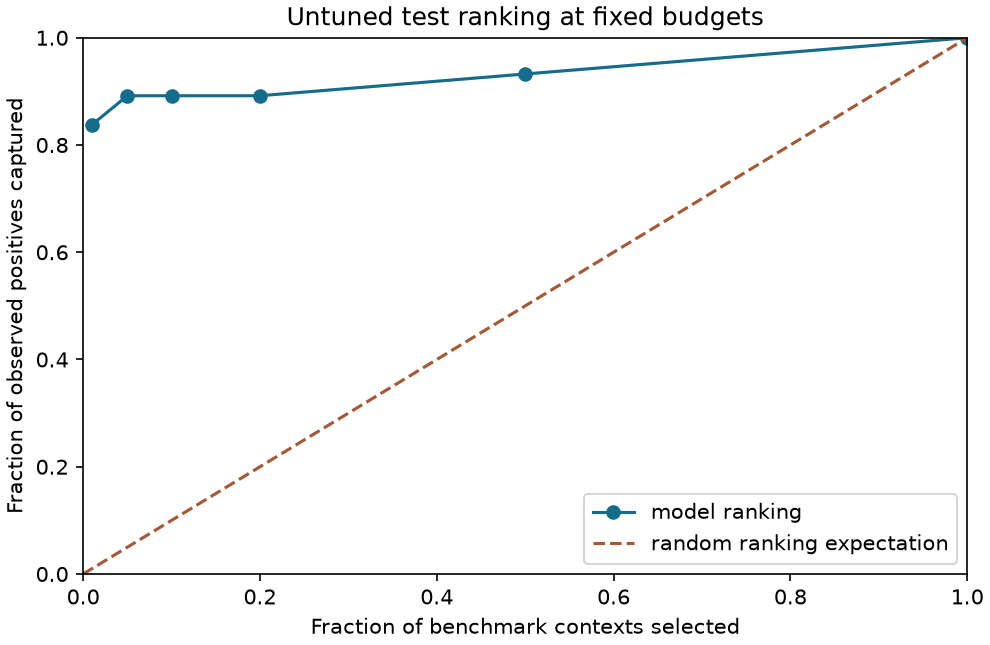

In [7]:
display(pd.read_csv('results/phase2/operating_policies.csv'))
display(Image(filename='results/phase2/ranking.png'))

## Interpretation

Three expanding chronological validation windows test stability. The forest uses 60 trees and at most 40,000 fitting rows per tree, keeping runtime bounded. An independent calibration reserve adjusts score scale. Investigation budgets and relative error costs are explicit assumptions; no recovered-dollar claim is made.

Run `python demo.py`, then open the local URL printed by the server. The demo scores public validation examples and compares frozen validation-derived review policies. Costs are hypothetical relative units; the cost recommendation uses validation outcomes only. The server binds to loopback, restricts routes and payload size, and writes no request data.